# TP 4 — Assembler et entraîner le modèle complet

Tokens (+ positions) → Attention multi-têtes → LayerNorm et MLP → ×4 blocs résiduels → Unembedding et Softmax

**Résultat attendu :** une loss d'entraînement et de validation qui diminue, puis environ 2 000 caractères générés dans un style progressivement reconnaissable — sans exiger un anglais correct.

> Dans Colab : *Exécution → Modifier le type d'exécution → GPU*. Exécutez le notebook dans l'ordre.

## Étape 0 — Préparer le notebook

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F

batch_size = 16
block_size = 32
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)
torch.manual_seed(1337)

cuda


In [2]:
from urllib.request import urlretrieve
import os
import torch
import torch.nn as nn
from torch.nn import functional as F

url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
if not os.path.exists("input.txt"):
    urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join([itos[i] for i in ids])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)

print(len(text), vocab_size)

1115394 65


### Questions d'interprétation

- **d_h = n_emb / n_head** = 64 / 4 = **16**.
- **Tokens par batch :** B × T = 16 × 32 = **512** prédictions par pas.
- **Sur CPU, quelle variable réduire d'abord pour tester ?** `max_iters` (par ex. 200–500) : le temps total est proportionnel au nombre d'itérations sans changer le modèle. On peut aussi baisser `eval_iters`, puis seulement ensuite `block_size` / `n_layer`.

## Étape 1 — Coder une tête

In [3]:
class Head(nn.Module):
    """Une tête d'auto-attention causale."""

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape                                   # (B, T, n_embd)
        k, q = self.key(x), self.query(x)                   # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5    # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)                        # (B, T, T)
        wei = self.dropout(wei)
        v = self.value(x)                                   # (B, T, hs)
        return wei @ v                                      # (B, T, hs)

h = Head(16)
print(h(torch.randn(16, 32, 64)).shape)   # attendu : (16, 32, 16)

torch.Size([16, 32, 16])


### Questions d'interprétation

**Pourquoi `k.size(-1)` plutôt que C pour le facteur d'échelle ?** La variance du produit scalaire q·k dépend de la dimension des queries/keys, c'est-à-dire d_h = `head_size` (16), et non de la dimension d'entrée C = n_emb (64). Diviser par √C sous-normaliserait.

**Pourquoi tronquer `tril[:T,:T]` ?** Le buffer est créé pour la taille maximale `block_size`, mais une séquence peut être plus courte (en génération au début, T commence à 1). Le masque doit avoir la forme (T, T) des scores.

## Étape 2 — Combiner plusieurs têtes

In [4]:
class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, puis projection."""

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)   # 4 × (B,T,16) -> (B,T,64)
        return self.dropout(self.proj(out))                   # (B,T,64)

mha = MultiHeadAttention(n_head, n_embd // n_head)
print(mha(torch.randn(16, 32, 64)).shape)

torch.Size([16, 32, 64])


### Questions d'interprétation

**Pourquoi concaténer sur la dernière dimension ?** Chaque tête produit, pour chaque (b, t), un vecteur de d_h features. On veut juxtaposer ces features pour chaque token — pas ajouter des tokens ni des éléments de batch — donc on concatène sur l'axe des features (`dim=-1`).

**Si n_emb n'était pas divisible par n_head ?** `head_size = n_embd // n_head` serait arrondi vers le bas, la concaténation aurait n_head·d_h < n_emb composantes et `self.proj` (qui attend n_emb entrées) lèverait une erreur de forme ; on ne pourrait pas non plus additionner la sortie au flux résiduel. D'où l'`assert` de l'étape 0.

## Étape 3 — Assembler un bloc

In [5]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Bloc Transformer : communication (attention) puis calcul (MLP)."""

    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # (B,T,C)
        x = x + self.ffwd(self.ln2(x))   # (B,T,C)
        return x

print(Block(n_embd, n_head)(torch.randn(16, 32, 64)).shape)

torch.Size([16, 32, 64])


### Questions d'interprétation

**Ordre :** pré-norm — on normalise l'entrée de la sous-couche (LayerNorm), on applique l'attention ou le MLP, puis on **ajoute** le résultat au flux résiduel `x`. Le flux résiduel lui-même n'est jamais normalisé dans le bloc.

**Communication / calcul :** la *communication* est l'attention multi-têtes, seule opération qui fait circuler l'information entre positions ; le *calcul* est le feed-forward, appliqué à chaque token séparément pour transformer ce qu'il a récolté.

## Étapes 4 et 5 — Définir les couches du modèle, le passage avant et la loss

In [6]:
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)               # (B, T, n_embd)
        pos = torch.arange(T, device=idx.device)                # (T,)
        pos_emb = self.position_embedding_table(pos)            # (T, n_embd)

        x = tok_emb + pos_emb                                   # (B, T, C) par broadcasting
        x = self.blocks(x)                                      # (B, T, C)
        x = self.ln_f(x)                                        # (B, T, C)
        logits = self.lm_head(x)                                # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            logits = logits.reshape(B*T, vocab_size)
            targets = targets.reshape(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        # idx : (B, T)
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]          # au plus block_size tokens
            logits, _ = self(idx_cond)               # (B, T, vocab_size)
            logits = logits[:, -1, :]                # (B, vocab_size)
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)   # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1)              # (B, T+1)
        return idx

In [7]:
# Vérification des formes
m = BigramLanguageModel()
xb, yb = get_batch('train')
xb, yb = xb.cpu(), yb.cpu()
logits, loss = m(xb)
print("logits sans cibles :", logits.shape)
logits, loss = m(xb, yb)
print("logits avec cibles :", logits.shape, "loss :", loss.item())
for name, p in [("token_embedding_table", m.token_embedding_table.weight),
                ("position_embedding_table", m.position_embedding_table.weight),
                ("lm_head", m.lm_head.weight)]:
    print(f"{name:25s} {tuple(p.shape)}")

logits sans cibles : torch.Size([16, 32, 65])
logits avec cibles : torch.Size([512, 65]) loss : 4.274328231811523
token_embedding_table     (65, 64)
position_embedding_table  (32, 64)
lm_head                   (65, 64)


### Questions d'interprétation (étape 4)

**Dimensions :** `token_embedding_table` : (65, 64) ; `position_embedding_table` : (32, 64) ; `lm_head` : poids (65, 64) (PyTorch stocke `out × in`), soit l'application 64 → 65, plus un biais de taille 65.

**Pourquoi `lm_head` n'est-il plus confondu avec l'embedding ?** Dans le bigramme, la même table C × C allait directement du caractère aux logits. Ici les vecteurs passent par un espace intermédiaire de dimension n_emb, contextualisé par les blocs : il faut une couche d'entrée (vocabulaire → n_emb) et une couche de sortie distincte (n_emb → vocabulaire). Cela découple aussi la taille du vocabulaire de la largeur du modèle.

### Questions d'interprétation (étape 5)

**Broadcasting :** `tok_emb` est (B, T, C) et `pos_emb` est (T, C). Les dimensions sont alignées par la droite ; `pos_emb` est traité comme (1, T, C) et répété sur les B séquences : chaque séquence reçoit les mêmes embeddings de position.

**Pourquoi ne pas aplatir les logits lors de la génération ?** On a besoin de la structure (B, T, vocab) pour sélectionner le dernier pas de temps de chaque séquence (`logits[:, -1, :]`). L'aplatissement ne sert qu'à `cross_entropy`, donc seulement quand des cibles sont fournies.

### Questions d'interprétation (étape 6 — génération)

**Pourquoi `@torch.no_grad()` ?** En génération, on ne calcule pas de gradient : PyTorch n'a pas à mémoriser le graphe de calcul, ce qui économise mémoire et temps.

**Pourquoi `multinomial` plutôt que `argmax` ?** `argmax` est déterministe et tend à boucler sur les mêmes suites les plus probables. Échantillonner selon la distribution respecte les probabilités apprises et produit un texte varié.

**Pourquoi `idx[:, -block_size:]` ?** L'embedding de position n'a que `block_size` lignes et le masque `tril` est de taille `block_size` : le modèle ne peut traiter que T ≤ block_size.

## Étapes 7 et 8 — Évaluer puis entraîner

In [8]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out


def train(model, max_iters, eval_interval=eval_interval):
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    history = []
    for iteration in range(max_iters):
        if iteration % eval_interval == 0 or iteration == max_iters - 1:
            losses = estimate_loss()
            history.append((iteration, losses['train'].item(), losses['val'].item()))
            print(f"step {iteration}: train {losses['train']:.4f}, val {losses['val']:.4f}")

        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    return history

### Questions d'interprétation

**Pourquoi `model.eval()` puis `model.train()` ?** Certaines couches (Dropout, BatchNorm) se comportent différemment à l'entraînement et à l'évaluation. `eval()` désactive le dropout pour une mesure déterministe ; `train()` le réactive avant de reprendre l'apprentissage. (Avec `dropout = 0.0`, sans effet ici, mais c'est indispensable dès qu'on l'augmente.)

**Loss train qui baisse, validation qui remonte ?** C'est du **surapprentissage** : le modèle mémorise les particularités du jeu d'entraînement au lieu de généraliser. Remèdes : augmenter le dropout, réduire le modèle, arrêter plus tôt, ou utiliser plus de données.

## Étape 9 — Entraîner, générer et expérimenter

In [9]:
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, 'M paramètres')

# Génération AVANT entraînement
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=300)[0].tolist()))

0.209729 M paramètres

?YfzxbDkRZ'Nzc.wj,ZTkOLFL,yptK
b:!PeCkbBbzAU3eXaSKgO-33jM:c?gL3auhXbYVXJtpXfNuwqcJ,$G.t?Vc dXl!DwaLeNFwccHPpRWk,fDEdaYzxzC$omX
Yow&$-MtofViEphB!H&V!OW;Kd!lNZ,Keg irYe-EOnUciK;lxW;HFGidroG EsSXUB;qWklJ.JGDW.3eWjbm!pelJljnFApVcu.$-huE3qcVcJvbN:pUup;Mnii'X3Uwty.OJlvBPUHI.3BfopeY-lgvIEjVkgDmlqwJdlNctS?k


In [10]:
# Test très court pour vérifier que tout tourne
_ = train(model, max_iters=200, eval_interval=100)

step 0: train 4.4109, val 4.4016
step 100: train 2.6511, val 2.6604
step 199: train 2.4923, val 2.4891


In [11]:
# Entraînement complet (repart d'un modèle neuf)
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
history = train(model, max_iters=max_iters)

step 0: train 4.4109, val 4.4016
step 100: train 2.6511, val 2.6604
step 200: train 2.4941, val 2.4902
step 300: train 2.3909, val 2.4026
step 400: train 2.3222, val 2.3292
step 500: train 2.2546, val 2.2712
step 600: train 2.1957, val 2.2057
step 700: train 2.1663, val 2.1891
step 800: train 2.1255, val 2.1531
step 900: train 2.0776, val 2.1118
step 1000: train 2.0562, val 2.0895
step 1100: train 2.0290, val 2.0836
step 1200: train 1.9990, val 2.0471
step 1300: train 1.9899, val 2.0369
step 1400: train 1.9541, val 2.0076
step 1500: train 1.9346, val 2.0005
step 1600: train 1.9225, val 2.0094
step 1700: train 1.9133, val 1.9922
step 1800: train 1.8801, val 1.9734
step 1900: train 1.8763, val 1.9607
step 2000: train 1.8529, val 1.9716
step 2100: train 1.8479, val 1.9635
step 2200: train 1.8353, val 1.9440
step 2300: train 1.8282, val 1.9341
step 2400: train 1.8214, val 1.9242
step 2500: train 1.7963, val 1.9271
step 2600: train 1.7978, val 1.9137
step 2700: train 1.7942, val 1.9243
step

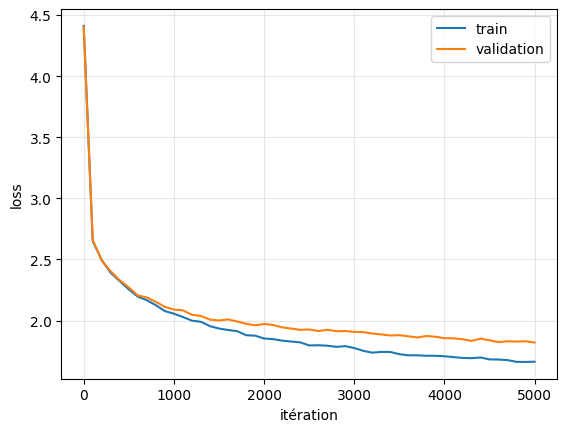

In [12]:
import matplotlib.pyplot as plt

steps, tr, va = zip(*history)
plt.plot(steps, tr, label='train')
plt.plot(steps, va, label='validation')
plt.xlabel('itération'); plt.ylabel('loss'); plt.legend(); plt.grid(alpha=.3)
plt.show()

In [13]:
# Génération APRÈS entraînement
context = torch.zeros((1, 1), dtype=torch.long, device=device)
result = model.generate(context, max_new_tokens=2000)
print(decode(result[0].tolist()))


And they bridle.

SOLORETESH:

becannoblanouge.
Stirt'd the gatause: thething will his barteth.

GLesswered Rome:
Go, where my Yourself fortain!
But where in at misters, I in latest in ov the does flow.

PAULINA:
Welll no me us thus, congivy: tugh are thee you love.
In Bodiet-lives, but you, thou again Will to thee in sound myself?
Edwere in From of my hours
To kingngnrumied so;
And his shall dying of the padere?

KING HENRY-PLINCE:
O, discateds be his grest huth couraman teyour-bust,
And for the neet. Pome, guilts you haste?
 so a cemssed-spent betwerting, and thou such swond the beggent of
confespy that that lome
Is as detter in stroesed Peepent over:
Hendst comment if meed; buse stings his remes to Lony,
Who lovescess is good duke one.

xut Corach!
Hear that fraving with some. Do year For these late.

PETHIBY:
He hone,-his I sweed poiven'd.

POLIXENES:
Hence of time the should eyself, will there whoe than the rugless welll keep you have the with twatch the
stort in noth;
you welthe

## Expériences

Chaque expérience recrée le modèle : les classes lisent les constantes globales (`block_size`, `n_head`, `dropout`) au moment de leur construction. Réduisez `exp_iters` sur CPU.

In [14]:
def experiment(exp_iters=2000, **overrides):
    global block_size, n_head, dropout
    saved = dict(block_size=block_size, n_head=n_head, dropout=dropout)
    globals().update(overrides)
    try:
        global model
        torch.manual_seed(1337)
        model = BigramLanguageModel().to(device)
        print(overrides, f"{sum(p.numel() for p in model.parameters())/1e6:.3f} M paramètres")
        h = train(model, max_iters=exp_iters, eval_interval=exp_iters // 4)
        return h[-1]
    finally:
        globals().update(saved)

exp_iters = 2000
resultats = {}

In [15]:
# 3. block_size = 16, puis 64
for bs in (16, 64):
    resultats[f"block_size={bs}"] = experiment(exp_iters, block_size=bs)

{'block_size': 16} 0.209 M paramètres
step 0: train 4.3481, val 4.3419
step 500: train 2.2736, val 2.2679
step 1000: train 2.0895, val 2.1280
step 1500: train 1.9773, val 2.0531
step 1999: train 1.9370, val 2.0221
{'block_size': 64} 0.212 M paramètres
step 0: train 4.3399, val 4.3492
step 500: train 2.3103, val 2.3151
step 1000: train 2.0937, val 2.1218
step 1500: train 1.9251, val 2.0003
step 1999: train 1.8225, val 1.9412


In [16]:
# 4. 1 tête, puis 4 têtes à n_embd constant
for nh in (1, 4):
    resultats[f"n_head={nh}"] = experiment(exp_iters, n_head=nh)

{'n_head': 1} 0.210 M paramètres
step 0: train 4.3833, val 4.3757
step 500: train 2.2125, val 2.2159
step 1000: train 2.0254, val 2.0698
step 1500: train 1.9022, val 1.9964
step 1999: train 1.8330, val 1.9402
{'n_head': 4} 0.210 M paramètres
step 0: train 4.4109, val 4.4016
step 500: train 2.2753, val 2.2767
step 1000: train 2.0637, val 2.0954
step 1500: train 1.9339, val 2.0078
step 1999: train 1.8573, val 1.9508


In [17]:
# 5. Dropout plus élevé (utile si un surapprentissage apparaît)
resultats["dropout=0.2"] = experiment(exp_iters, dropout=0.2)

{'dropout': 0.2} 0.210 M paramètres
step 0: train 4.4109, val 4.4016
step 500: train 2.3296, val 2.3282
step 1000: train 2.1465, val 2.1587
step 1500: train 2.0338, val 2.0786
step 1999: train 1.9636, val 2.0242


In [18]:
print(f"{'expérience':18s} {'train':>8s} {'val':>8s}")
for k, (_, tr, va) in resultats.items():
    print(f"{k:18s} {tr:8.4f} {va:8.4f}")

expérience            train      val
block_size=16        1.9370   2.0221
block_size=64        1.8225   1.9412
n_head=1             1.8330   1.9402
n_head=4             1.8573   1.9508
dropout=0.2          1.9636   2.0242


## Bilan des quatre TP

| Classe / fonction | Notion du cours |
|---|---|
| `encode` / `decode`, `get_batch` | tokenisation, paires (contexte, cible) décalées |
| `token_embedding_table` | identité du token → vecteur de dimension n_emb |
| `position_embedding_table` | information d'ordre (position dans le contexte) |
| `Head`, `MultiHeadAttention` | auto-attention causale Q, K, V |
| `nn.LayerNorm` | normalisation de chaque token sur ses features |
| `FeedForward` | MLP C → 4C → C appliqué token par token |
| `Block` | pré-norm + connexions résiduelles |
| `ln_f`, `lm_head` | unembedding vers les logits du vocabulaire |
| `F.cross_entropy`, `generate` | loss / Softmax et échantillonnage autorégressif |

- **Quelle brique crée le contexte ?** L'attention (multi-têtes) : c'est la seule où un token reçoit de l'information des tokens précédents.
- **Laquelle transforme un token ?** Le feed-forward (avec LayerNorm), appliqué indépendamment à chaque position.
- **Laquelle produit les logits ?** `lm_head` (après `ln_f`).
- **Où la loss agit-elle sur l'ensemble du modèle ?** La cross-entropy est calculée sur les logits, puis `loss.backward()` rétropropage le gradient à travers `lm_head`, tous les blocs (MLP, attention, LayerNorm) jusqu'aux deux tables d'embedding ; `optimizer.step()` met ensuite à jour tous ces paramètres. Les connexions résiduelles assurent que ce gradient atteint efficacement les premières couches.

## Observations

- **Entraînement complet (5 000 itérations, 0,21 M paramètres) :** la loss passe de 4,41 à **1,66 (train)** et **1,82 (validation)**, bien en dessous du bigramme (≈ 2,5). L'écart train/val s'élargit légèrement en fin d'entraînement (≈ 0,16) mais la validation baisse encore : pas de vrai surapprentissage.
- **Texte généré :** structure de pièce de théâtre (noms de personnages en majuscules, répliques, vers courts), de vrais mots anglais et des noms du corpus (PAULINA, POLIXENES, ISABELLA…), mêlés à des mots inventés.
- **block_size :** 64 donne une meilleure validation que 16 (1,94 contre 2,02 après 2 000 itérations) : plus de contexte, meilleures prédictions.
- **Nombre de têtes :** 1 tête (1,94) et 4 têtes (1,95) sont quasiment à égalité après 2 000 itérations. L'écart est inférieur au bruit d'un seul essai ; l'avantage du multi-têtes apparaît plutôt sur des entraînements plus longs ou des modèles plus grands.
- **dropout = 0,2 :** validation moins bonne (2,02). Normal : il n'y avait pas de surapprentissage à corriger, et le dropout ralentit l'apprentissage sur un entraînement court.
